In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

print("Libraries imported successfully")

Libraries imported successfully


In [5]:
df = pd.read_csv("project1_algorithmic_pricing_synthetic_dataset.csv")

df["date"] = pd.to_datetime(df["date"])
intervention_date = pd.Timestamp("2025-05-01")

print("Dataset shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Regions:", df["region"].unique())
display(df.head())

Dataset shape: (540, 11)
Date range: 2025-01-01 00:00:00 to 2025-06-29 00:00:00
Regions: <StringArray>
['North', 'South', 'West']
Length: 3, dtype: str


,date,region,product_category,our_price,competitor_price,units_sold,revenue,marketing_spend,promotion_active,treatment,period
0,2025-01-01,North,Home Essentials,501.50,494.80,101,50651.59,474.38,0,0,pre_treatment
1,2025-01-01,South,Home Essentials,489.38,490.19,100,48937.65,417.33,0,0,pre_treatment
2,2025-01-01,West,Home Essentials,509.40,511.37,118,60109.02,449.37,0,0,pre_treatment
3,2025-01-02,North,Home Essentials,499.37,502.85,109,54431.06,345.83,0,0,pre_treatment
4,2025-01-02,South,Home Essentials,486.93,494.56,107,52101.37,381.01,0,0,pre_treatment


In [6]:
daily_revenue = (
    df.groupby(["date", "region"])["revenue"]
    .sum()
    .reset_index()
)

wide_df = daily_revenue.pivot(
    index="date",
    columns="region",
    values="revenue"
).reset_index()

wide_df = wide_df.sort_values("date").reset_index(drop=True)

print("Wide dataset shape:", wide_df.shape)
display(wide_df.head())

Wide dataset shape: (180, 4)


region,date,North,South,West
0,2025-01-01,50651.59,48937.65,60109.02
1,2025-01-02,54431.06,52101.37,62082.51
2,2025-01-03,62516.51,53274.36,57028.24
3,2025-01-04,67241.10,60980.94,65800.24
4,2025-01-05,66825.20,66908.57,69358.06


In [7]:
pre_data = wide_df[wide_df["date"] < intervention_date].copy()
post_data = wide_df[wide_df["date"] >= intervention_date].copy()

print("Pre-treatment dates:", len(pre_data))
print("Post-treatment dates:", len(post_data))
print("Pre-period:", pre_data["date"].min(), "to", pre_data["date"].max())
print("Post-period:", post_data["date"].min(), "to", post_data["date"].max())

Pre-treatment dates: 120
Post-treatment dates: 60
Pre-period: 2025-01-01 00:00:00 to 2025-04-30 00:00:00
Post-period: 2025-05-01 00:00:00 to 2025-06-29 00:00:00


In [8]:
north_pre = pre_data["North"].to_numpy()
donor_pre = pre_data[["South", "West"]].to_numpy()

def objective(weights):
    synthetic = donor_pre @ weights
    return np.mean((north_pre - synthetic) ** 2)

result = minimize(
    objective,
    x0=np.array([0.5, 0.5]),
    method="SLSQP",
    bounds=[(0, 1), (0, 1)],
    constraints=[{"type": "eq", "fun": lambda w: np.sum(w) - 1}],
)

if not result.success:
    raise RuntimeError(f"Weight optimization failed: {result.message}")

south_weight, west_weight = result.x

print(f"South weight: {south_weight:.4f}")
print(f"West weight: {west_weight:.4f}")
print(f"Weight sum: {result.x.sum():.4f}")
print(f"Pre-treatment MSE: {result.fun:.2f}")

South weight: 0.5000
West weight: 0.5000
Weight sum: 1.0000
Pre-treatment MSE: 36627510.23


In [9]:
wide_df["synthetic_north"] = (
    south_weight * wide_df["South"]
    + west_weight * wide_df["West"]
)

wide_df["gap"] = (
    wide_df["North"] - wide_df["synthetic_north"]
)

wide_df["period"] = np.where(
    wide_df["date"] < intervention_date,
    "Pre-treatment",
    "Post-treatment"
)

display(wide_df.head())

region,date,North,South,West,synthetic_north,gap,period
0,2025-01-01,50651.59,48937.65,60109.02,54523.335,-3871.745,Pre-treatment
1,2025-01-02,54431.06,52101.37,62082.51,57091.940,-2660.880,Pre-treatment
2,2025-01-03,62516.51,53274.36,57028.24,55151.300,7365.210,Pre-treatment
3,2025-01-04,67241.10,60980.94,65800.24,63390.590,3850.510,Pre-treatment
4,2025-01-05,66825.20,66908.57,69358.06,68133.315,-1308.115,Pre-treatment


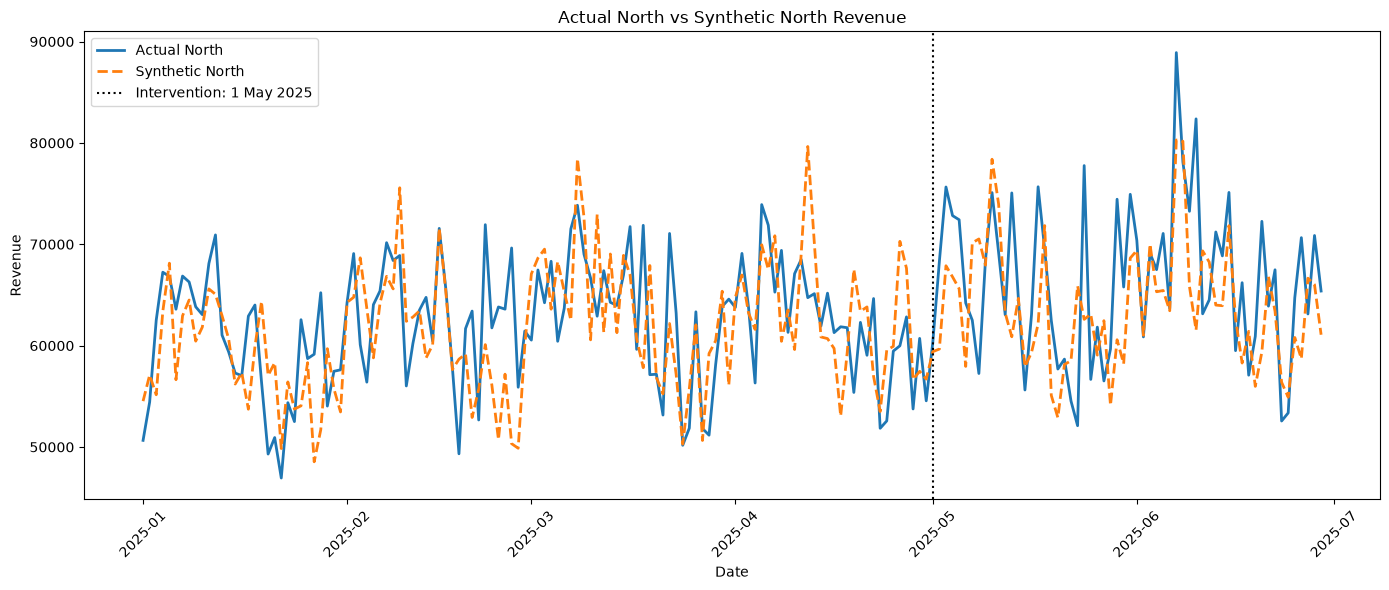

In [10]:
plt.figure(figsize=(14, 6))

plt.plot(
    wide_df["date"],
    wide_df["North"],
    label="Actual North",
    linewidth=2
)

plt.plot(
    wide_df["date"],
    wide_df["synthetic_north"],
    label="Synthetic North",
    linestyle="--",
    linewidth=2
)

plt.axvline(
    intervention_date,
    color="black",
    linestyle=":",
    label="Intervention: 1 May 2025"
)

plt.title("Actual North vs Synthetic North Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
post_results = wide_df[
    wide_df["date"] >= intervention_date
].copy()

average_effect = post_results["gap"].mean()
cumulative_effect = post_results["gap"].sum()

print(f"Average daily estimated gap: {average_effect:,.2f}")
print(f"Cumulative estimated gap: {cumulative_effect:,.2f}")

display(
    post_results[["date", "North", "synthetic_north", "gap"]].head()
)

Average daily estimated gap: 2,537.58
Cumulative estimated gap: 152,254.85


region,date,North,synthetic_north,gap
120,2025-05-01,60337.35,59400.045,937.305
121,2025-05-02,68332.15,59663.065,8669.085
122,2025-05-03,75650.15,67877.635,7772.515
123,2025-05-04,72824.00,66779.695,6044.305
124,2025-05-05,72417.73,65614.515,6803.215


In [12]:
wide_df.to_csv("synthetic_control_results.csv", index=False)

print("Saved: synthetic_control_results.csv")

Saved: synthetic_control_results.csv
